# Batched photonic-lantern propagation with a DM-driven input PSF

Loads a DM influence function, uses it to generate a *batch*
of aberrated input pupil fields, and propagates the whole batch through a
characterized photonic-lantern `ChainPropagator` in a single call -- then
reconstructs the output fields, visualizes them, and extracts per-core
output signals aligned to the lantern's ideal hex-grid layout.

`specula` is optional: the influence function (`ifunc/ANDES_400pix_all_modes.fits`)
is loaded through specula when it is installed and with plain numpy (plus
astropy, to read the FITS file) otherwise, and the results are bit-identical
either way. For a pure numpy-vs-JAX / batched-vs-one-at-a-time efficiency
comparison, see `Batched.ipynb`.

The lantern is the preset named by the environment variable `CBEAM_LANTERN`
(`pl19_800`, the reference 19-port lantern at 800 nm, by default; or
`pl7_1200`, `pl19_1200` -- see `batch_pipeline.LANTERNS`). Executed copies
for each lantern are in `runs/<lantern>/`.


In [1]:
import os
os.environ["CBEAM_BACKEND"] = "jax"

import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


## Import the batch pipeline

In [2]:
from batch_pipeline import *
from cbeam.waveguide import hex_ring_positions

# Ideal (unit-pitch) hex-grid layout of the lantern's output ports, pulled
# from the library instead of hand-typed: get_simulation_parameters() builds
# the *actual* port layout via
# output_positions = hex_ring_positions(nrings, rclad / ring_div) (see
# batch_pipeline/config.py) -- same function, just physical microns instead
# of unit pitch.
#
# Sorted row by row only to make the listing readable --
# map_evaluated_to_ideal_geometry() does not depend on the order.
ideal_grid_positions = sorted(
    hex_ring_positions(N_RINGS, 1.0),
    key=lambda pt: (round(pt[1], 2), round(pt[0], 2)),
)
assert len(ideal_grid_positions) == N_SIGNALS, (
    f"hex_ring_positions(N_RINGS, 1.0) returned {len(ideal_grid_positions)} "
    f"positions but the pipeline expects N_SIGNALS={N_SIGNALS} output ports."
)

print(f"Batch pipeline imported successfully ({len(ideal_grid_positions)} output ports)")


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


Using JAX backend.


Using diffrax for ODE integration.


Batch pipeline imported successfully (19 output ports)


## Optional: profiling helper

A small utility that manually replays the setup steps
`BatchPropagationPipeline.__init__` performs for one wavelength, timing each
one individually. It does **not** build a real pipeline -- it's read-only
profiling against an already-built `prop12`, used a couple of cells further
down.

In [3]:
import time
import numpy as np

from batch_pipeline import (
    get_waveguide_properties,
    IncidentFieldGenerator,
    ModalProjector,
    BatchPropagationPipeline,
    DEFAULT_GRID_RESOLUTION,
)


def profile_pipeline_preset(prop12, p, ifunc, grid_resolution=DEFAULT_GRID_RESOLUTION):
    """
    Manually replays BatchPropagationPipeline.__init__'s steps for one
    wavelength, timing each one. Does NOT construct a real pipeline --
    this is read-only profiling against an already-built prop12.
    """
    timings = {}

    t0 = time.perf_counter()
    wvg_props_input = get_waveguide_properties(prop12, mesh_z=0)
    t1 = time.perf_counter()
    timings["get_waveguide_properties(input, mesh_z=0)"] = t1 - t0

    wvg_props_output = get_waveguide_properties(prop12, mesh_z=p["z_ex"])
    t2 = time.perf_counter()
    timings["get_waveguide_properties(output, mesh_z=z_ex)"] = t2 - t1

    field_gen = IncidentFieldGenerator(p, ifunc, xp=np)
    t3 = time.perf_counter()
    timings["IncidentFieldGenerator.__init__ (mask + ifunc_matrix)"] = t3 - t2

    field_gen.precompute_interpolation_weights(wvg_props_input["points"])
    t4 = time.perf_counter()
    timings["precompute_interpolation_weights"] = t4 - t3

    modal_proj = ModalProjector(wvg_props_input, xp=np)
    t5 = time.perf_counter()
    timings["ModalProjector.__init__"] = t5 - t4

    # Replicates _precompute_delaunay_grid without needing a fully
    # constructed BatchPropagationPipeline instance.
    dummy = BatchPropagationPipeline.__new__(BatchPropagationPipeline)
    dummy.wvg_props_output = wvg_props_output
    _ = dummy._precompute_delaunay_grid(grid_resolution)
    t6 = time.perf_counter()
    timings[f"_precompute_delaunay_grid(resolution={grid_resolution})"] = t6 - t5

    print("\n" + "=" * 60)
    print("PRESET-PHASE TIMING BREAKDOWN")
    print("=" * 60)
    total = t6 - t0
    for label, dt in timings.items():
        bar = "#" * max(1, int(40 * dt / max(total, 1e-9)))
        print(f"{dt:7.3f} s  {bar:<40s}  {label}")
    print("-" * 60)
    print(f"{total:7.3f} s  TOTAL")
    print("=" * 60)

    return timings


## Simulation parameters

In [4]:
p = get_simulation_parameters()   # the lantern named by CBEAM_LANTERN (default pl19_800)
print(f"lantern {p['lantern']}: {p['n_output_positions']} ports at {p['wavelength_nm']:.0f} nm")

print("\n" + "="*60)
print("SIMULATION PARAMETERS")
print("="*60)
print(f"Wavelength: {p['wl']} μm")
print(f"Lantern length: {p['z_ex']} μm")
print(f"Cladding radius: {p['rclad']} μm")
print(f"Jacket radius: {p['rjack']} μm")
print(f"Core radius: {p['rcore']:.3f} μm")
print(f"Taper factor: {p['taper_factor']}")
print(f"Available influence function: {p['ifunc_file']}")


lantern pl19_1200: 19 ports at 1200 nm

SIMULATION PARAMETERS
Wavelength: 1.2 μm
Lantern length: 100000 μm
Cladding radius: 10.0 μm
Jacket radius: 30.0 μm
Core radius: 0.220 μm
Taper factor: 15.0
Available influence function: /raid1/frossi/dev/work/cbeam/examples/ifunc/ANDES_400pix_all_modes.fits


## Load the influence function and build the propagator

`load_ifunc()` returns specula's `IFunc` when specula is installed and the
plain-numpy `SimpleIFunc` otherwise. `batch_pipeline` only reads the
object's `.mask_inf_func` / `.influence_function` arrays, and both loaders
hand it bit-identical ones, so nothing downstream depends on which was used.
Set `USE_SPECULA` to `True` / `False` to force one or the other.

In [5]:
USE_SPECULA = None   # None: use specula if installed; True / False: force

print("Loading influence function...")
print(p["ifunc_file"])
ifunc = load_ifunc(p["ifunc_file"], use_specula=USE_SPECULA)
print(f"  loaded as {type(ifunc).__module__}.{type(ifunc).__name__}")

# Re-center the mask: diagnose_input_psf() below flags an off-center mask as
# a PSF-alignment problem, so fix it up front rather than fighting it later.
shift_y, shift_x = center_ifunc_mask(ifunc)
print('shift_x, shift_y', shift_x, shift_y)

print(f"  Influence function modes: {len(ifunc.influence_function)}")

print("\nBuilding photonic lantern propagator...")
# reuse_cache=True: load a previously saved characterization for this
# (port-count, wavelength) instead of recomputing it (minutes -> seconds).
# The cache tag does NOT encode taper_factor / resolutions / radii (see
# build_and_characterize_lantern's docstring) -- if you change those, delete
# the matching files under ./data/ or pass reuse_cache=False to force a
# fresh characterization.
prop12 = build_and_characterize_lantern(p, reuse_cache=True)

print(f"  Propagator type: {type(prop12).__name__}")
print(f"  Total z range: {prop12.zs[0]:.0f} to {prop12.zs[-1]:.0f} μm")


2026-11-05 23:32:15,920 [INFO]: [iteras]: Cupy import successfull. Installed version is: 14.1.1


2026-11-05 23:32:15,921 [INFO]: [iteras]: Default device is CPU


Loading influence function...
/raid1/frossi/dev/work/cbeam/examples/ifunc/ANDES_400pix_all_modes.fits


  loaded as specula.data_objects.ifunc.IFunc
shift_x, shift_y 0 0
  Influence function modes: 10

Building photonic lantern propagator...


  loaded cached characterization 'pl19_1200_1200_front'


  loaded cached characterization 'pl19_1200_1200_back'


  Propagator type: ChainPropagator
  Total z range: 0 to 100000 μm


## Build the batch propagation pipeline

Creating batch propagation pipeline...



[Interpolation Setup]
  Padded grid size: 1600
  Grid parity: even
  Center offset: 800.0
  Pixel scale: 0.6150890459132873 μm/pixel
  Mesh X range: [-30.000, 30.000] μm
  Mesh Y range: [-29.836, 29.836] μm
  Valid interpolation points: 11739 / 11739

=== RUNNING INPUT PSF CENTERING & SCALE DIAGNOSTIC ===

[MASK CENTERING CHECK]
  Mask shape: (400, 400)
  Mask centroid: (199.49, 199.81)
  Expected center: (200.00, 200.00)
  Offset: (-0.513, -0.192) pixels

[FFT GRID CHECK]
  FFT grid shape: (1600, 1600)
  FFT center index: (800, 800)
  PSF peak index: (np.int64(800), np.int64(800))
  Centering offset: (np.int64(0), np.int64(0)) pixels
  PSF centroid (subpixel): (799.999, 799.997)
  Centroid offset: (-0.001, -0.003) pixels



[MESH INTERPOLATION CHECK]
  Mesh PSF peak: (0.075, -0.075) μm
  Nearest core (#0): distance = 0.106 μm

[COUPLING EFFICIENCY CHECK]
  Power inside the cladding (r < 10.0 μm): 96.7% of the power on the mesh
  Power coupled into the tracked modes: 42.9% of the focal-plane power


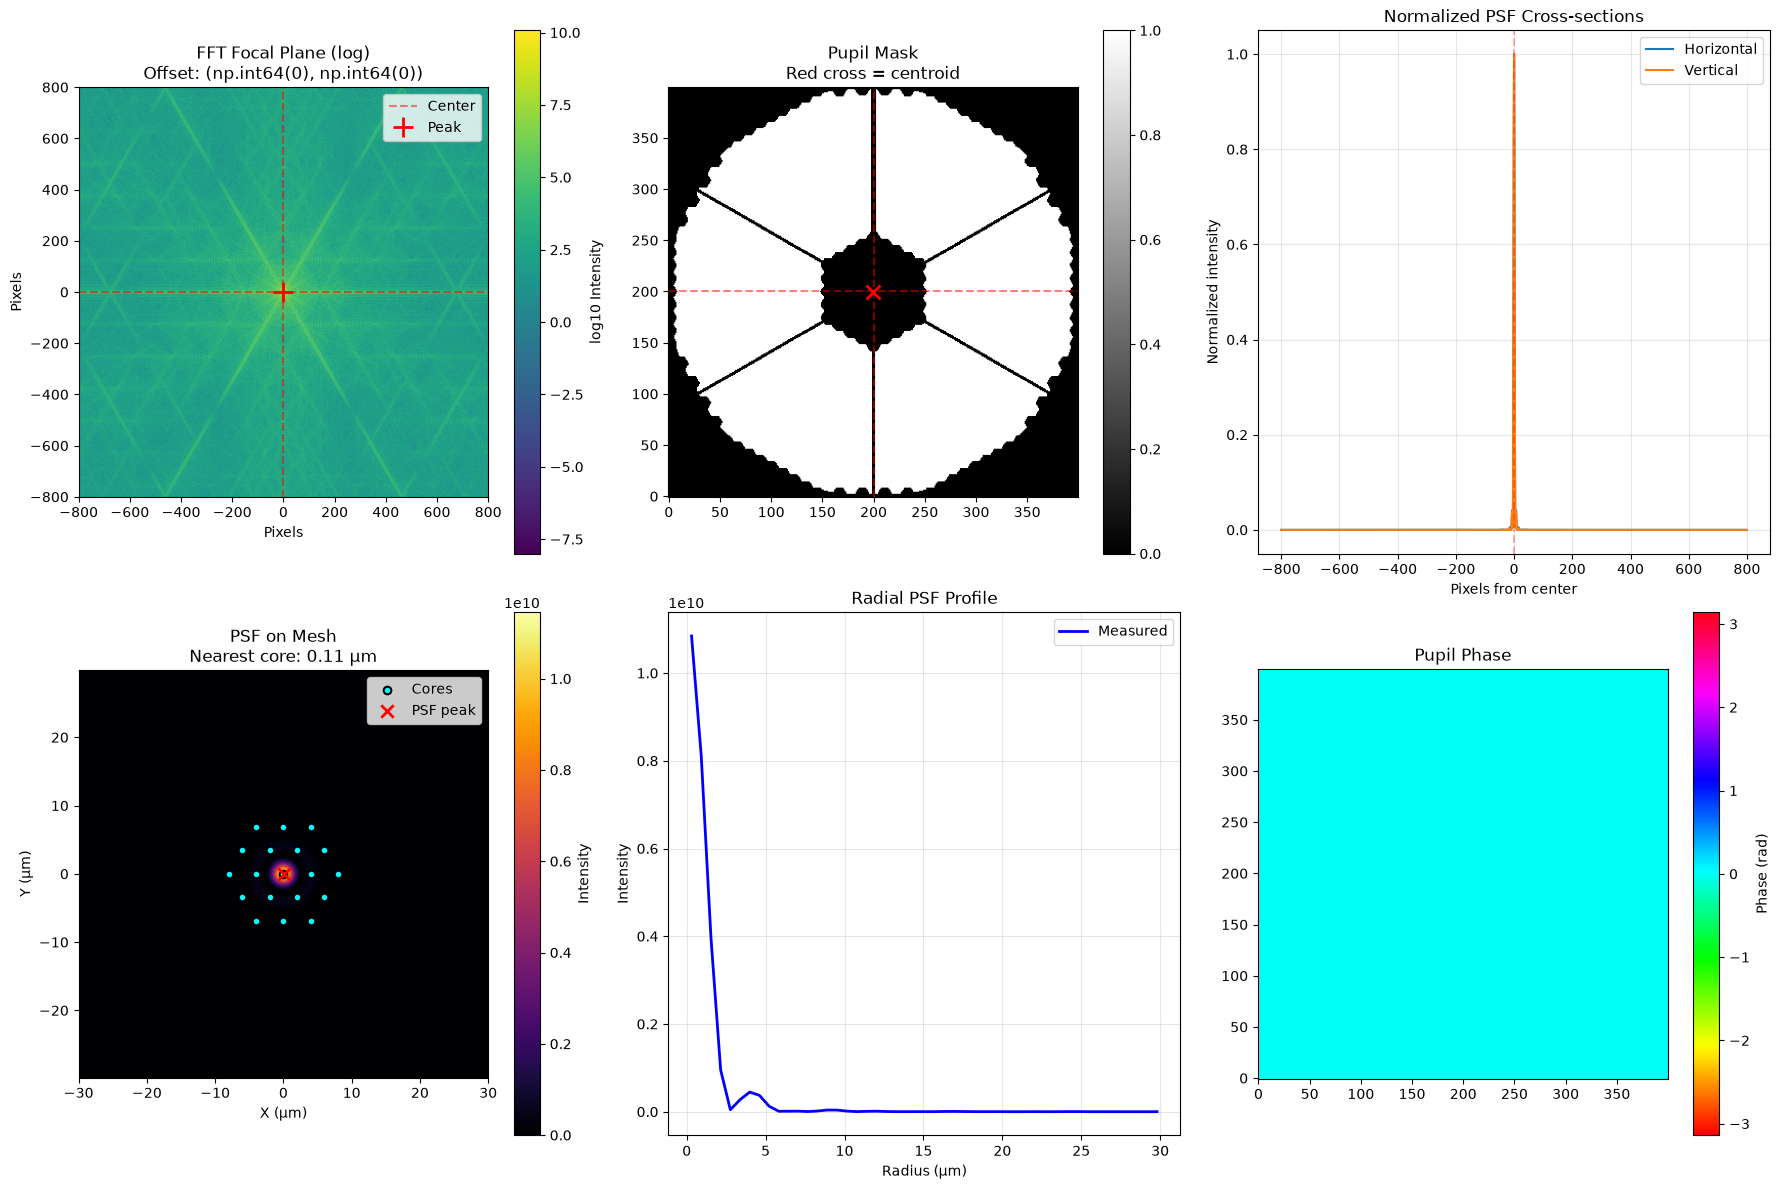


DIAGNOSTIC SUMMARY
✓ All checks passed - PSF appears well-centered
Waveguide Properties:
  Input modes: 20
  Output modes: 20
  Mesh points at input: 11739
  Mesh points at output: 11739


In [6]:
print("Creating batch propagation pipeline...\n")
pipeline = BatchPropagationPipeline(prop12, p, ifunc)

diagnose_input_psf(pipeline)

print("Waveguide Properties:")
print(f"  Input modes: {pipeline.wvg_props_input['n_modes']}")
print(f"  Output modes: {pipeline.wvg_props_output['n_modes']}")
print(f"  Mesh points at input: {pipeline.wvg_props_input['points'].shape[0]}")
print(f"  Mesh points at output: {pipeline.wvg_props_output['points'].shape[0]}")


## Optional: profile pipeline construction cost

In [7]:
profile_pipeline_preset(prop12, p, ifunc)


[Interpolation Setup]
  Padded grid size: 1600
  Grid parity: even
  Center offset: 800.0
  Pixel scale: 0.6150890459132873 μm/pixel
  Mesh X range: [-30.000, 30.000] μm
  Mesh Y range: [-29.836, 29.836] μm
  Valid interpolation points: 11739 / 11739



PRESET-PHASE TIMING BREAKDOWN
  0.015 s  #                                         get_waveguide_properties(input, mesh_z=0)
  0.012 s  #                                         get_waveguide_properties(output, mesh_z=z_ex)
  0.001 s  #                                         IncidentFieldGenerator.__init__ (mask + ifunc_matrix)
  0.001 s  #                                         precompute_interpolation_weights
  0.002 s  #                                         ModalProjector.__init__
  4.939 s  #######################################   _precompute_delaunay_grid(resolution=400)
------------------------------------------------------------
  4.970 s  TOTAL


{'get_waveguide_properties(input, mesh_z=0)': 0.014993346005212516,
 'get_waveguide_properties(output, mesh_z=z_ex)': 0.012227348983287811,
 'IncidentFieldGenerator.__init__ (mask + ifunc_matrix)': 0.0008468120358884335,
 'precompute_interpolation_weights': 0.0008824190008454025,
 'ModalProjector.__init__': 0.0020663890172727406,
 '_precompute_delaunay_grid(resolution=400)': 4.938546318968292}

## Generate aberration configurations

In [8]:
coeff0, _labels0 = create_random_aberration_configs(n=100, m=9, minv=-400, maxv=400)
coeff1, labels1 = create_ramp_aberration_configs([0], 20, 0, p["wavelength_nm"] / 2)   # mode 0 up to lambda/2


In [9]:
print("\nGenerating batch of input modal coefficients...\n")
print(coeff0.shape)
start_time = time.time()
u0_batch = pipeline.generate_batch_modal_coefficients(coeff0, use_gpu=False)
elapsed = time.time() - start_time
print(f"\ngenerate_batch_modal_coefficients Complete:")
print(f"  Elapsed time: {elapsed:.1f} seconds")
print(f"Input Modal Coefficient Batch:")
print(f"  Shape: {u0_batch.shape}")
print(f"  Dtype: {u0_batch.dtype}")
print(f"  Memory: {u0_batch.nbytes / 1e6:.1f} MB")

u1_batch = pipeline.generate_batch_modal_coefficients(coeff1, use_gpu=False)



Generating batch of input modal coefficients...

(100, 9)
  Generating modal coefficients for 100 fields (chunk_size=64, device=CPU) ...


    field-gen chunk 0–63 done.


    field-gen chunk 64–99 done.


  Field generation complete.

generate_batch_modal_coefficients Complete:
  Elapsed time: 3.2 seconds
Input Modal Coefficient Batch:
  Shape: (100, 20)
  Dtype: complex128
  Memory: 0.0 MB


## Propagate the batch through the lantern

In [10]:
print("\nPropagating batch through lantern...")
start_time = time.time()

uf_batch0, zs0, us_batch0 = pipeline.propagate_batch(u0_batch)
uf_batch1, zs1, us_batch1 = pipeline.propagate_batch(u1_batch)

elapsed = time.time() - start_time
print(f"\nPropagation Complete:")
print(f"  Elapsed time: {elapsed:.1f} seconds")
print(f"  Output modal coefficients shape: {uf_batch0.shape}")
print(f"  Propagation z-points: {len(zs0)}")



Propagating batch through lantern...
  Propagating 100 fields (chunk_size=10000) ...


    propagation chunk 0–99 done.


  Batch propagation complete.
  Propagating 20 fields (chunk_size=10000) ...


    propagation chunk 0–19 done.


  Batch propagation complete.

Propagation Complete:
  Elapsed time: 21.9 seconds
  Output modal coefficients shape: (100, 20)
  Propagation z-points: 2


## Reconstruct output spatial fields

In [11]:
print("Reconstructing output spatial fields...\n")

E_output_batch0 = pipeline.reconstruct_batch_output_fields(uf_batch0)
E_output_batch1 = pipeline.reconstruct_batch_output_fields(uf_batch1)

print(f"Output Spatial Fields:")
print(f"  Shape: {E_output_batch0.shape}")
print(f"  Dtype: {E_output_batch0.dtype}")
print(f"  Memory: {E_output_batch0.nbytes / 1e6:.1f} MB")


Reconstructing output spatial fields...



Output Spatial Fields:
  Shape: (100, 11739)
  Dtype: complex128
  Memory: 18.8 MB


## Interpolate to a regular grid

In [12]:
print("Interpolating output fields to regular grid...\n")

uf_2d_batch0, X_plot0, Y_plot0 = pipeline.interpolate_output_to_grid(E_output_batch0, grid_resolution=200)
uf_2d_batch1, X_plot1, Y_plot1 = pipeline.interpolate_output_to_grid(E_output_batch1, grid_resolution=200)

print(f"Interpolated Intensity Maps:")
print(f"  Shape: {uf_2d_batch0.shape}")
print(f"  X range: [{X_plot0.min():.2f}, {X_plot0.max():.2f}] μm")
print(f"  Y range: [{Y_plot0.min():.2f}, {Y_plot0.max():.2f}] μm")
print(f"  Memory: {uf_2d_batch0.nbytes / 1e6:.1f} MB")


Interpolating output fields to regular grid...



Interpolated Intensity Maps:
  Shape: (100, 200, 200)
  X range: [-450.00, 450.00] μm
  Y range: [-447.53, 447.53] μm
  Memory: 32.0 MB


## Visualize batch output

Generating visualization...



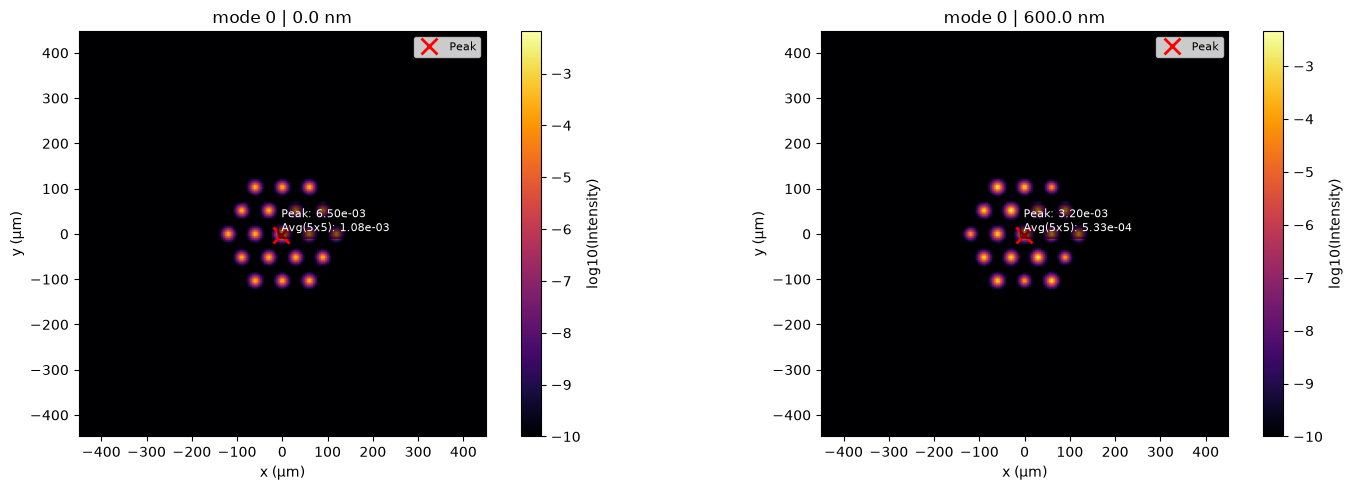

In [13]:
print("Generating visualization...\n")

# labels1 (built alongside coeff1 above) gives a human-readable title per
# ramp step, e.g. "mode 0 | 200.0 nm" -- show the first and last steps.
show_idx = [0, len(uf_2d_batch1) - 1]
titles = [labels1[i] for i in show_idx]

visualize_batch_output(uf_2d_batch1[show_idx], X_plot1, Y_plot1, titles,
                       max_fields=len(show_idx), show_arrow=False)


## Detect output core centres and align to the ideal hex grid

In [14]:
# Sum intensity across the ramp-batch fields so every core lights up at
# least once, then locate the output-core centres on that combined image.
first_intensity = uf_2d_batch0.sum(axis=0)
core_centers = detect_centers_from_grid(first_intensity, X_plot0, Y_plot0,
                                        n_expected=p["n_output_positions"])
print(f"Detected {len(core_centers)} core centers")

x_min, y_min = X_plot0[0, 0], Y_plot0[0, 0]
dx = X_plot0[0, 1] - X_plot0[0, 0]
dy = Y_plot0[1, 0] - Y_plot0[0, 0]

ideal_permutation = map_evaluated_to_ideal_geometry(core_centers, ideal_grid_positions)


[peaks] resolved 19 cores at threshold 0.100.
Detected 19 core centers
[Geometric Fit] Detected/ideal scale ratio: 60.044
[Geometric Fit] Residual rotation: -0.001 deg
[Geometric Fit] Residual matching RMS error: 4.7656e-03 (in units of the ideal layout)



## Extract per-core signals and display the hex-grid readout

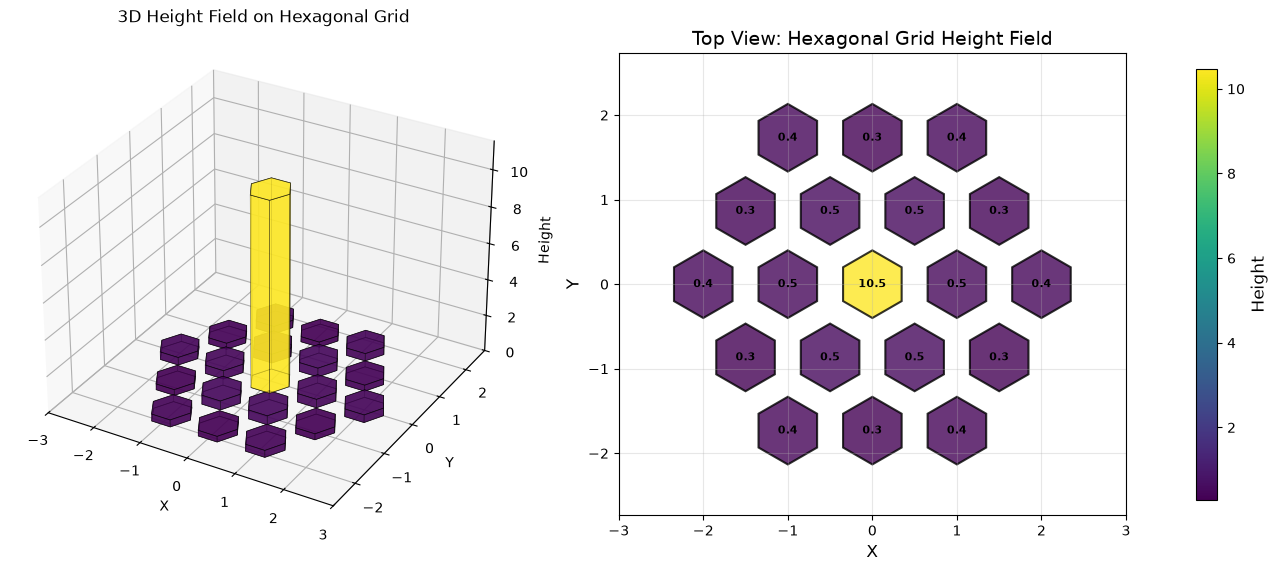

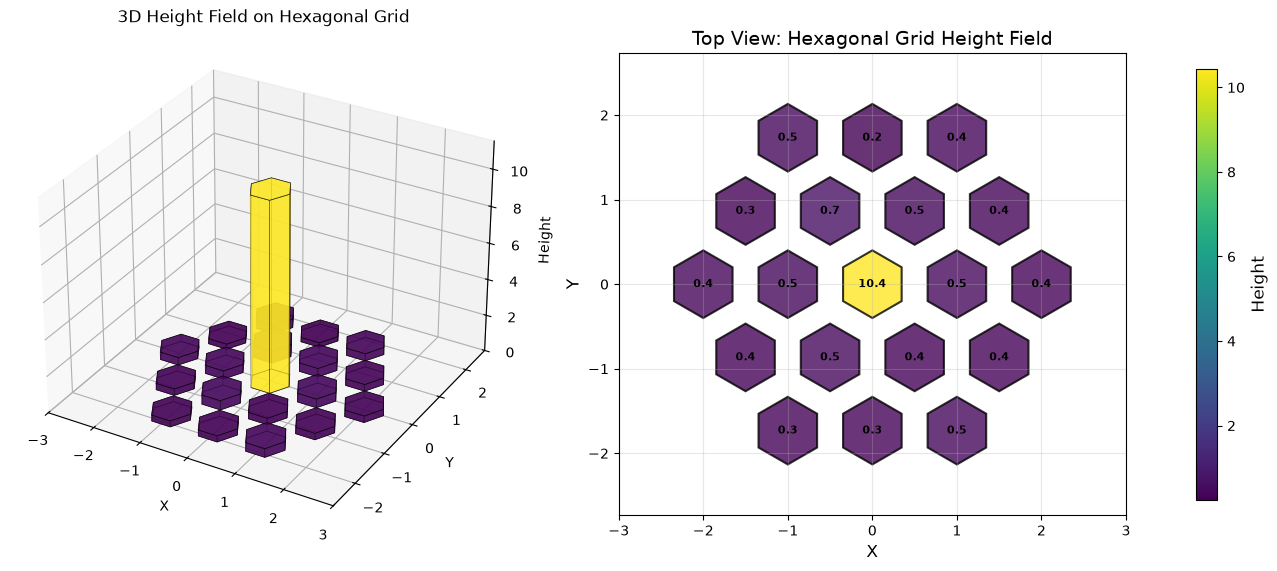

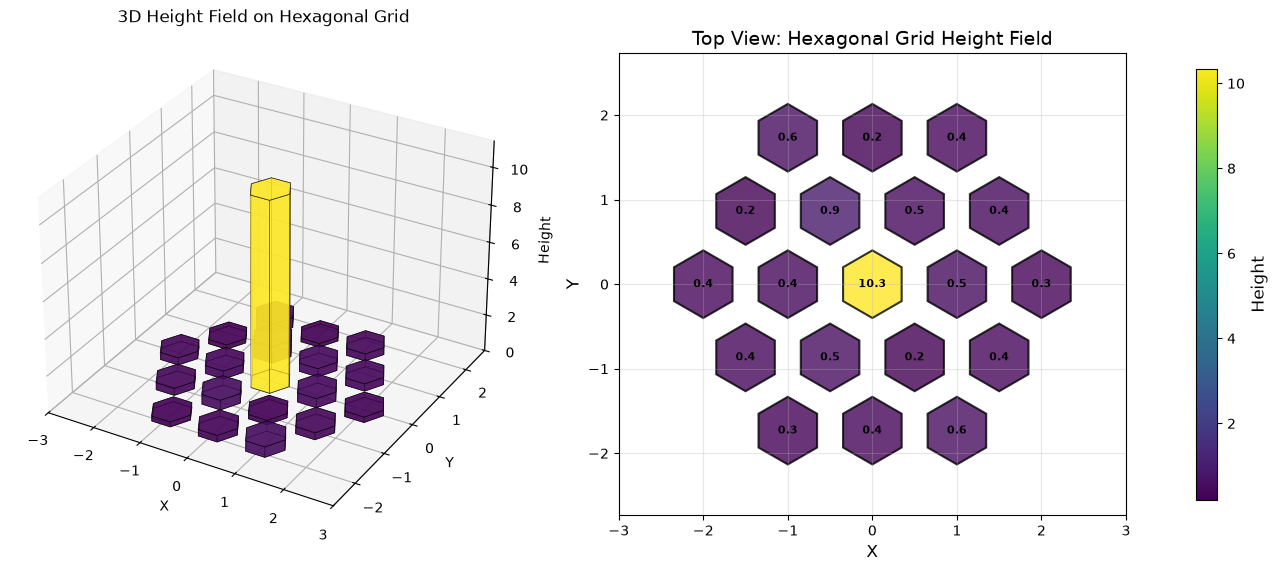

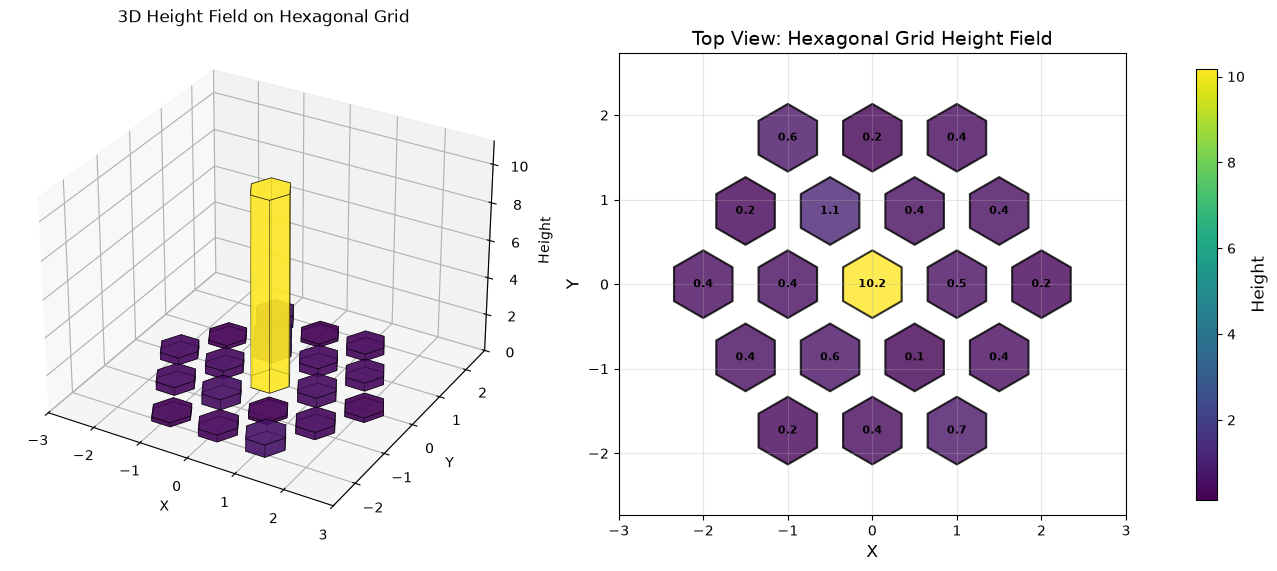

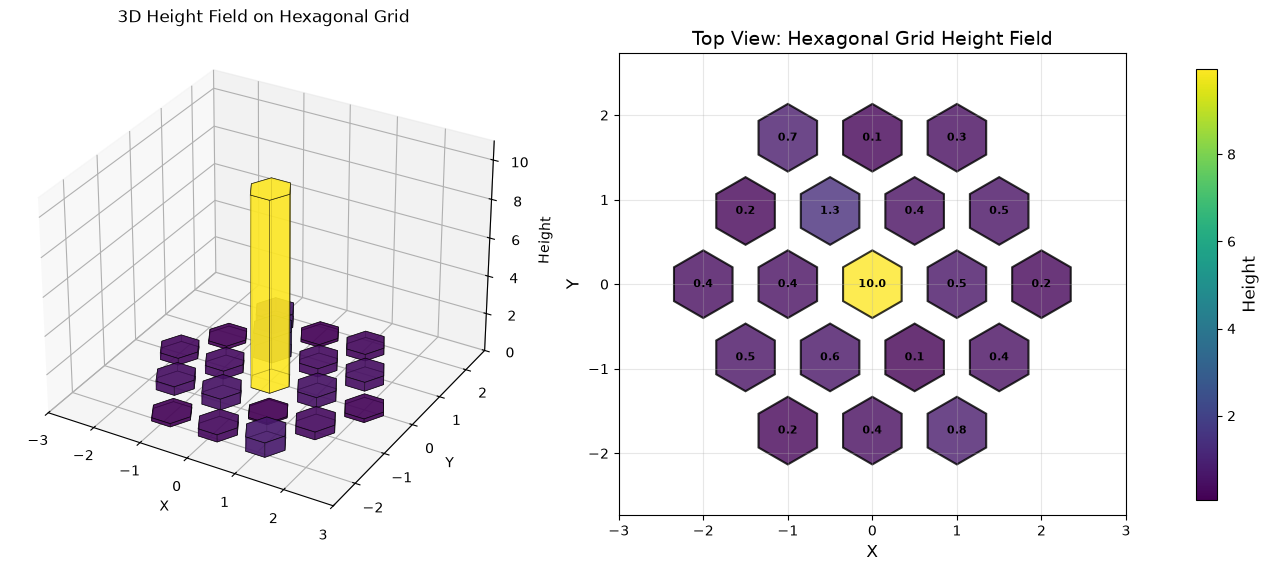

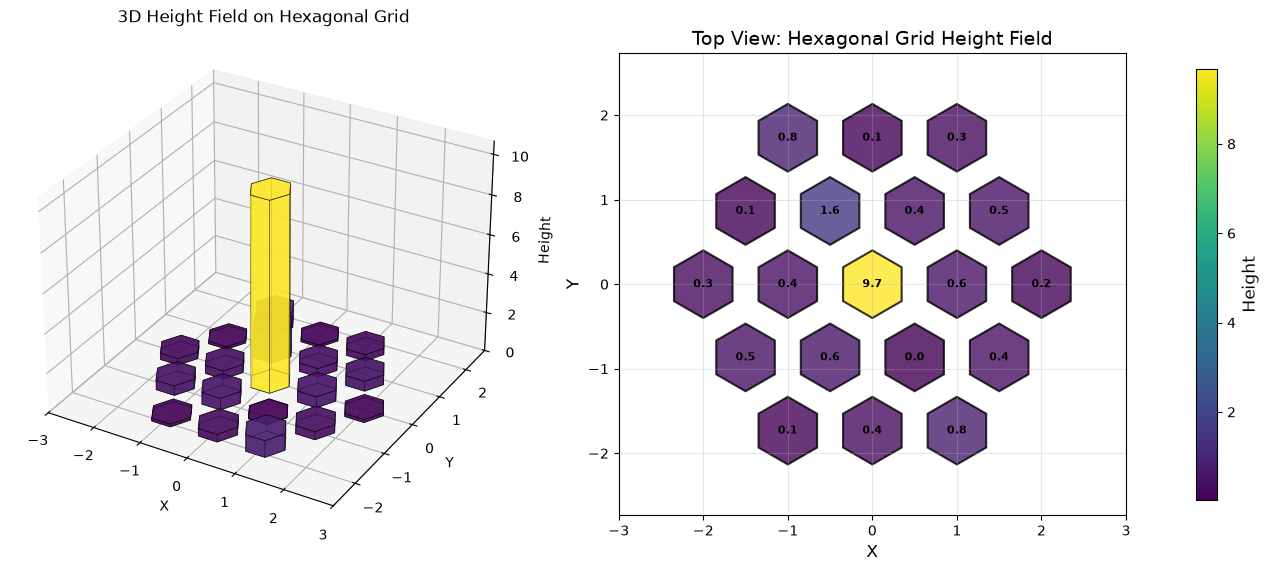

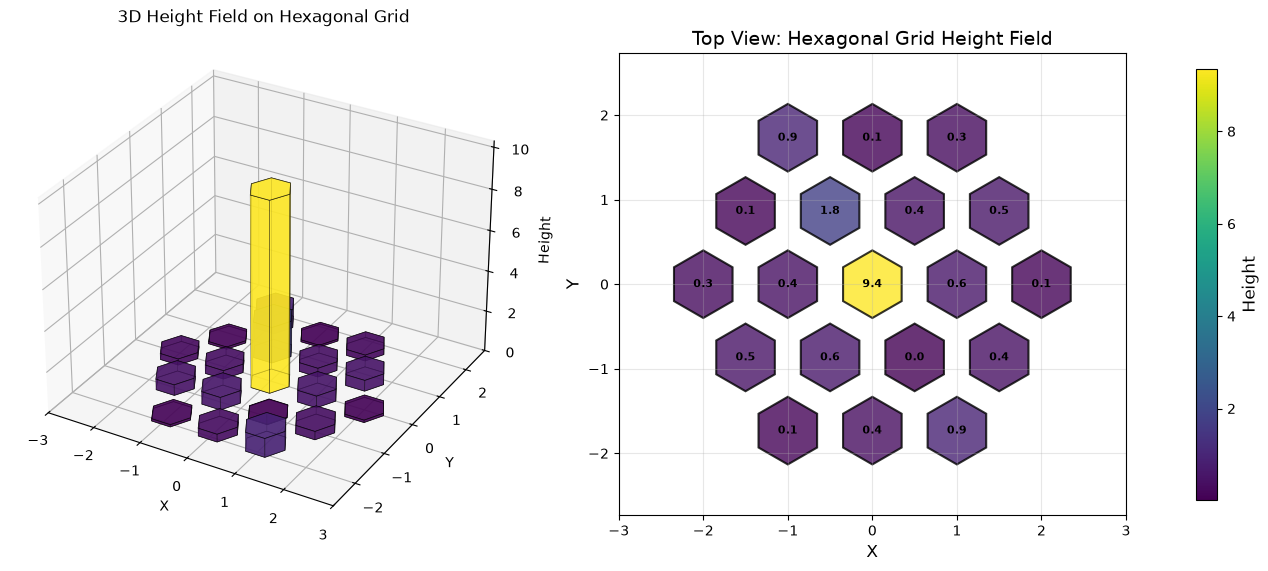

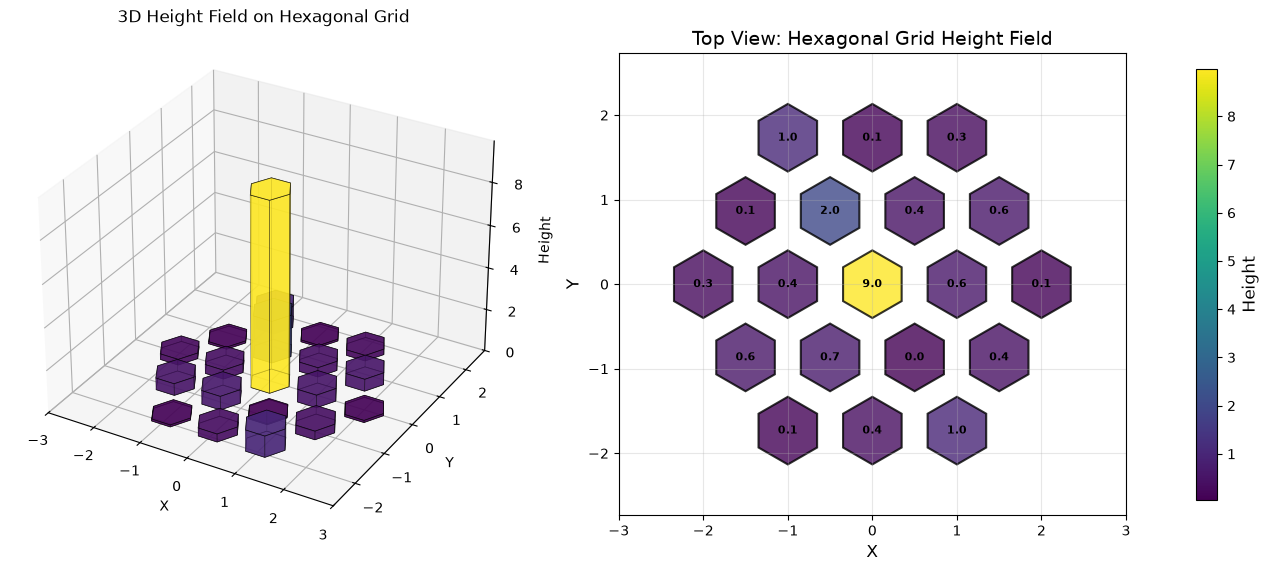

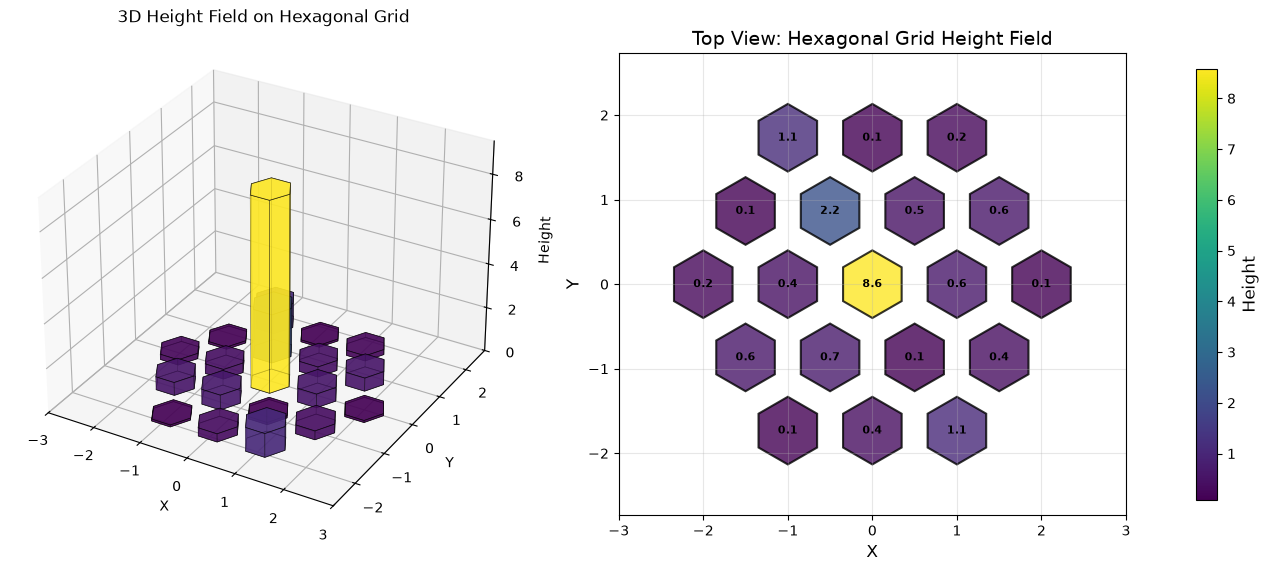

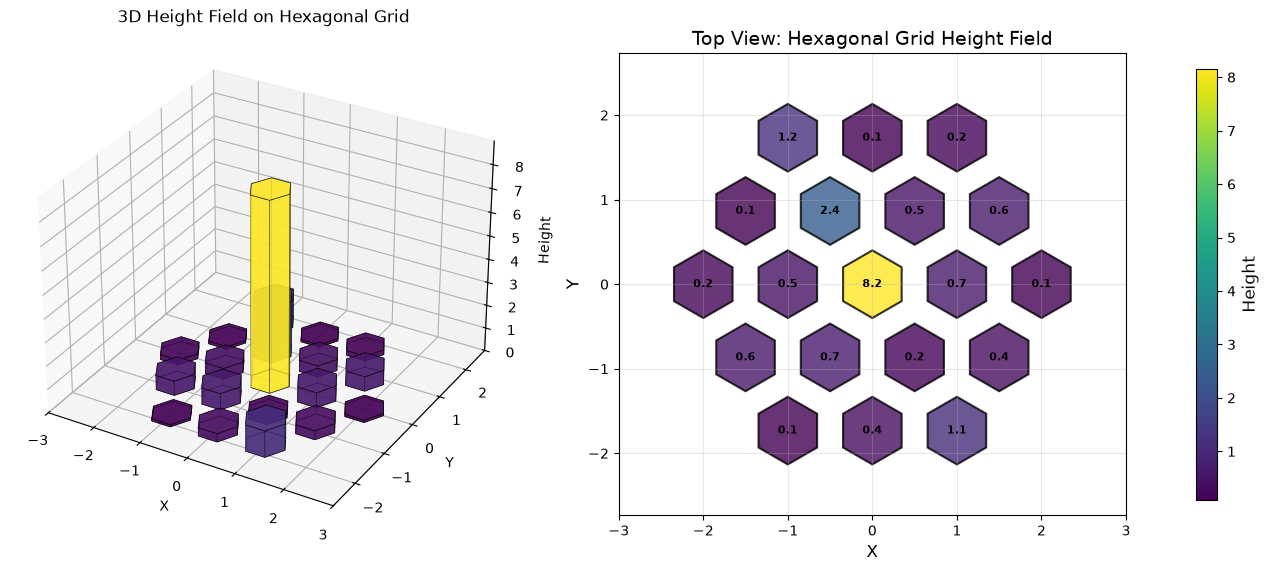

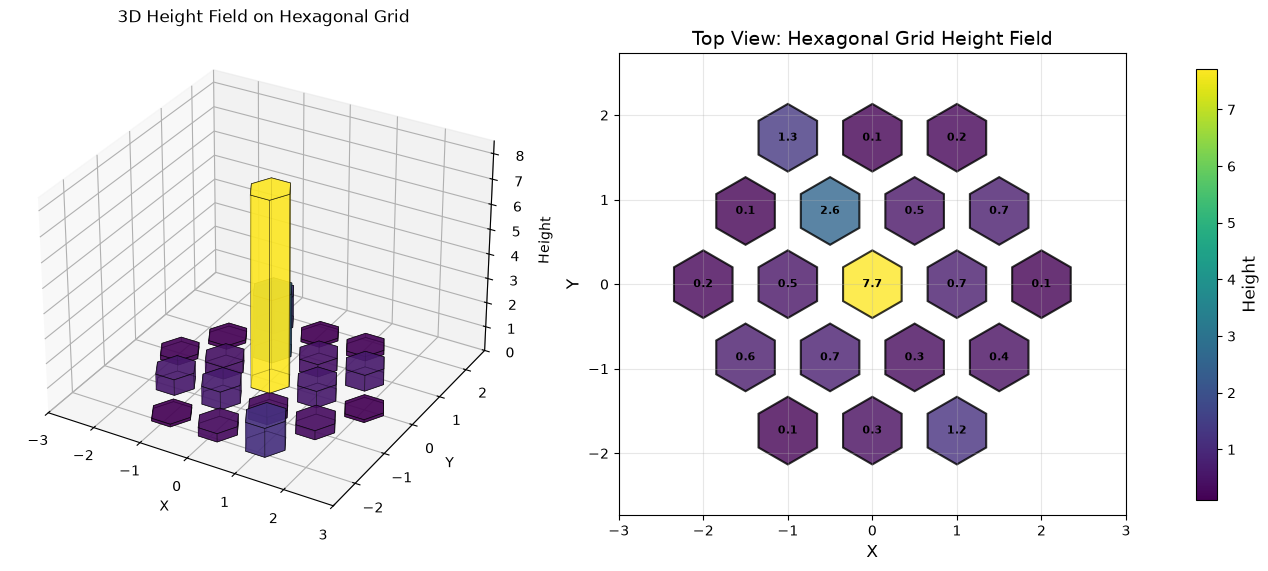

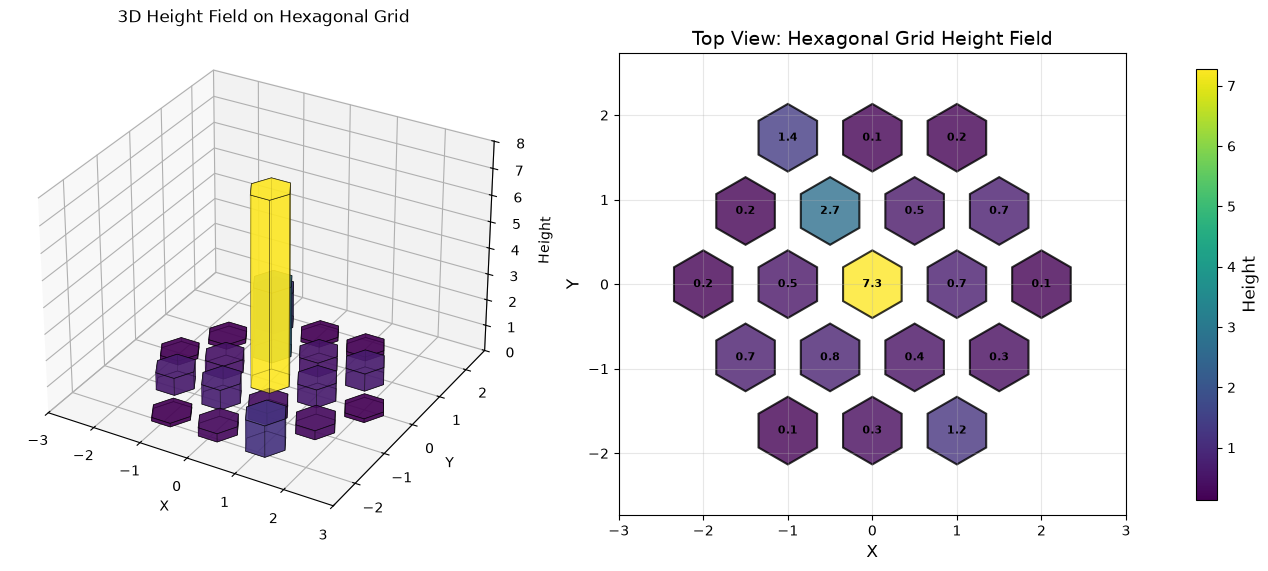

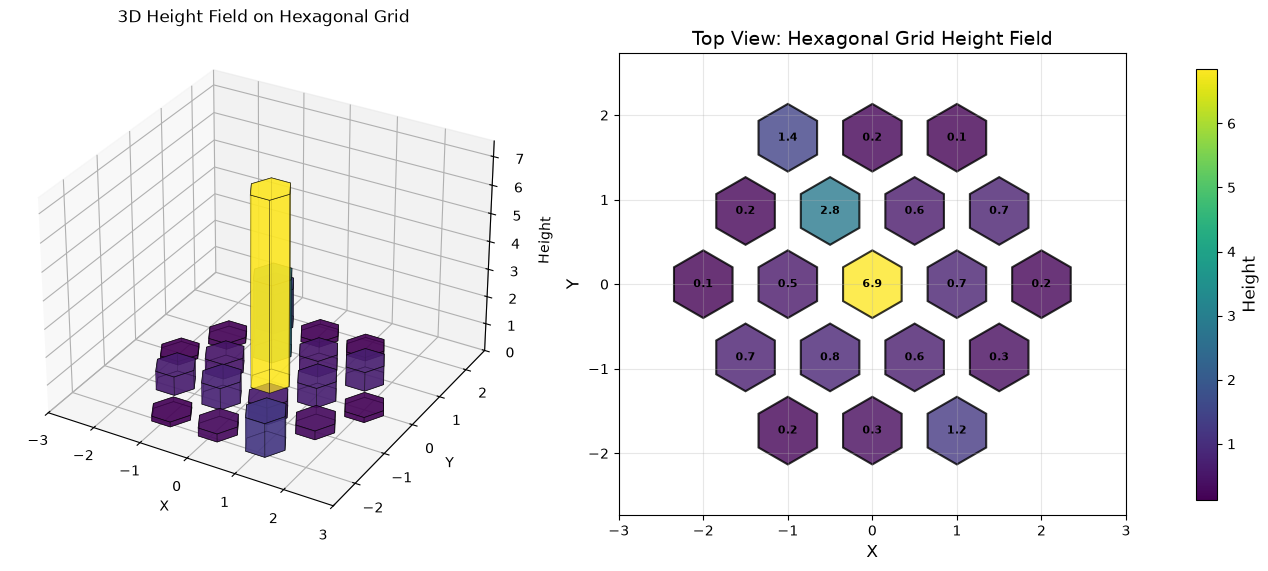

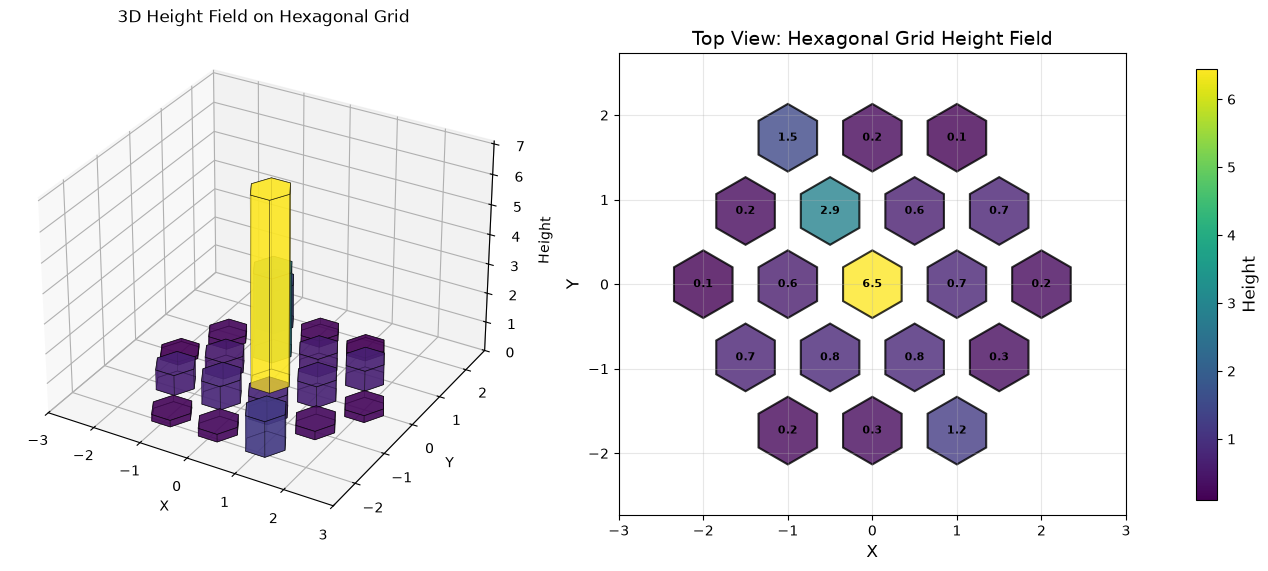

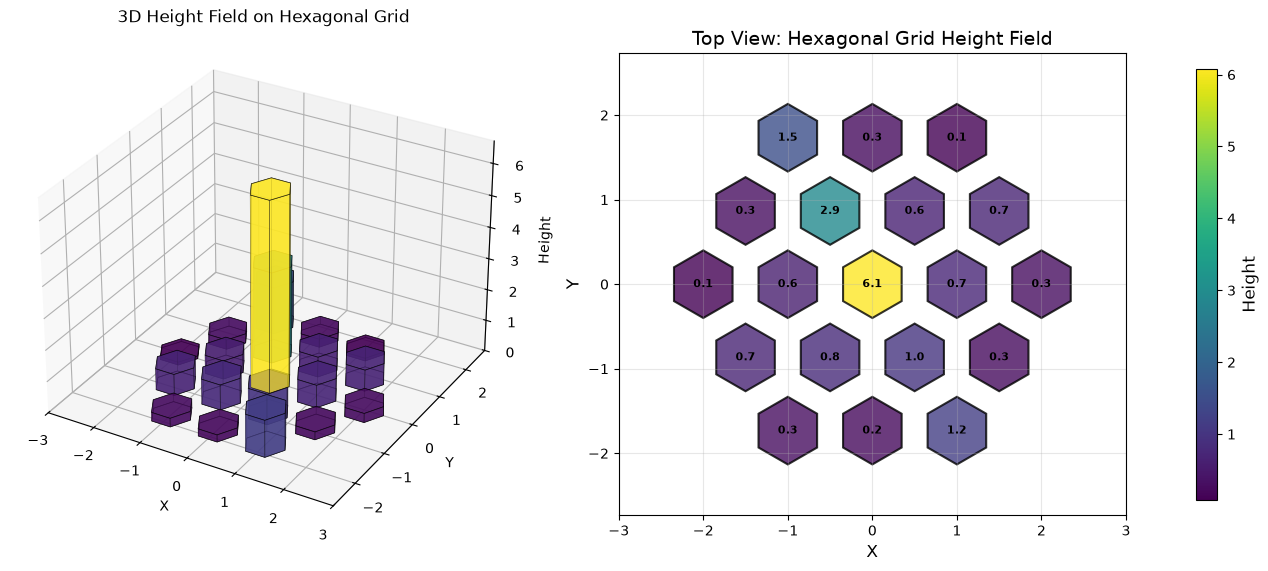

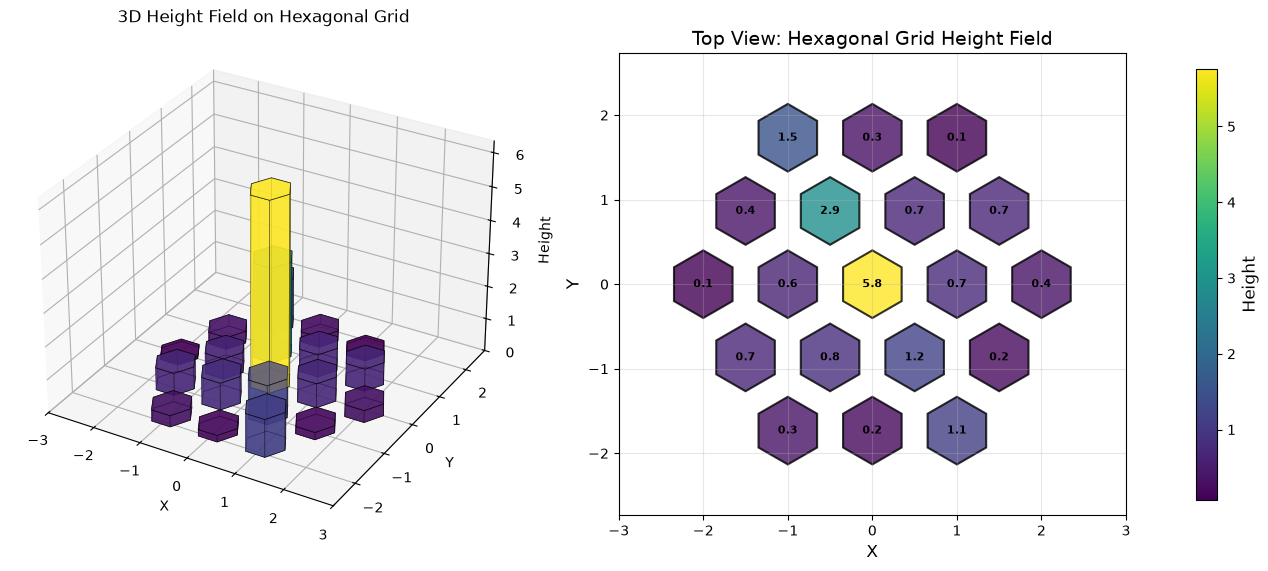

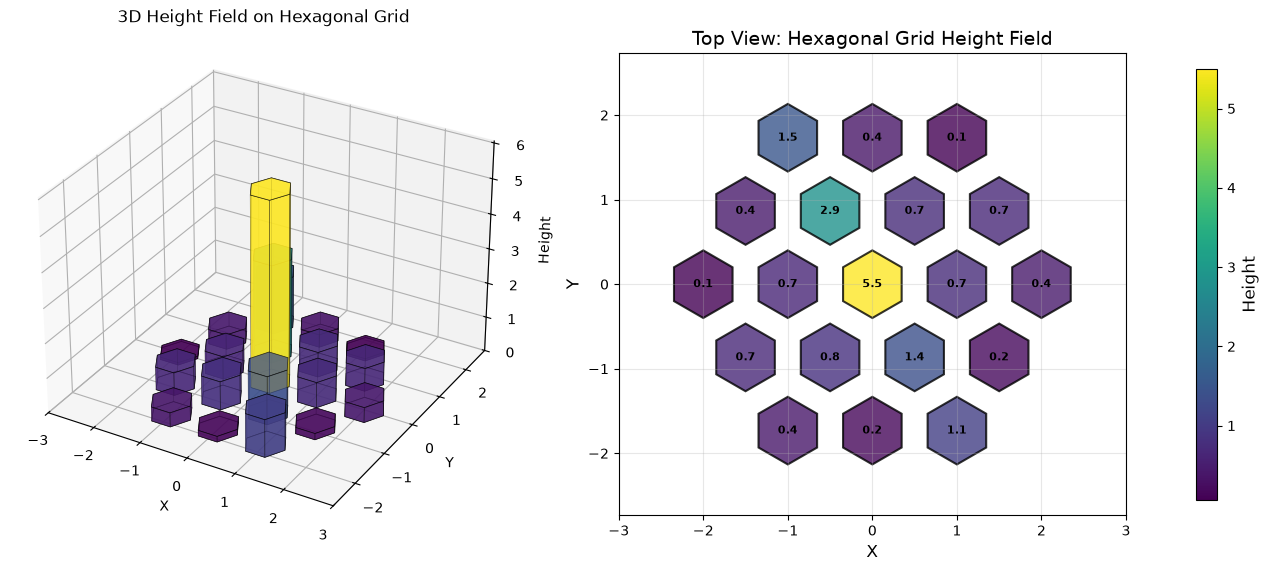

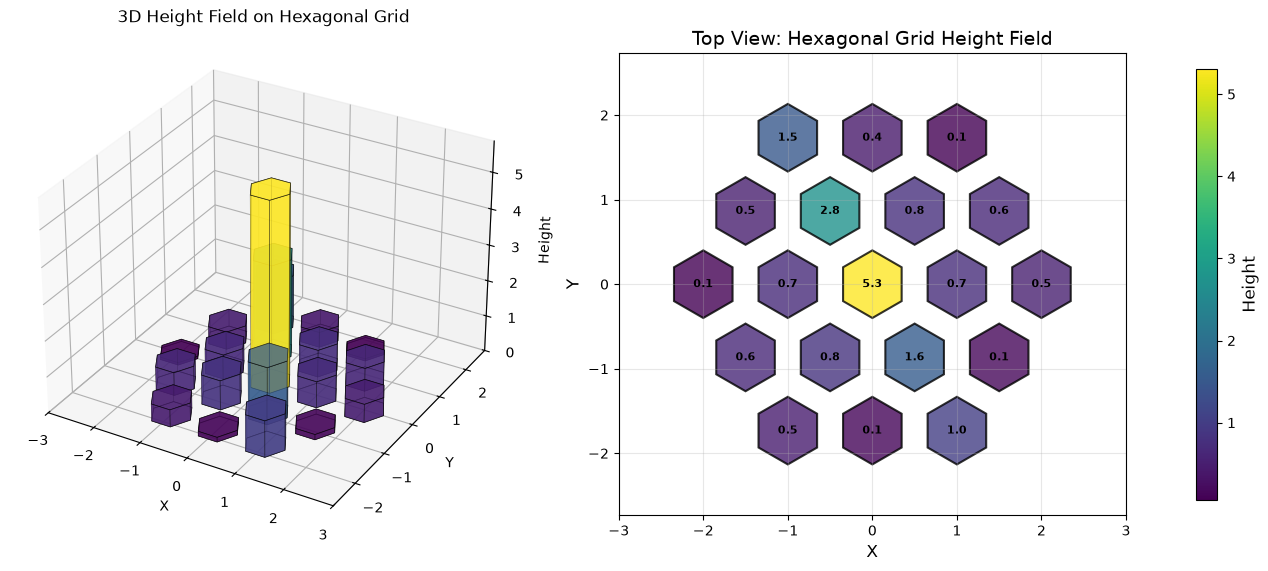

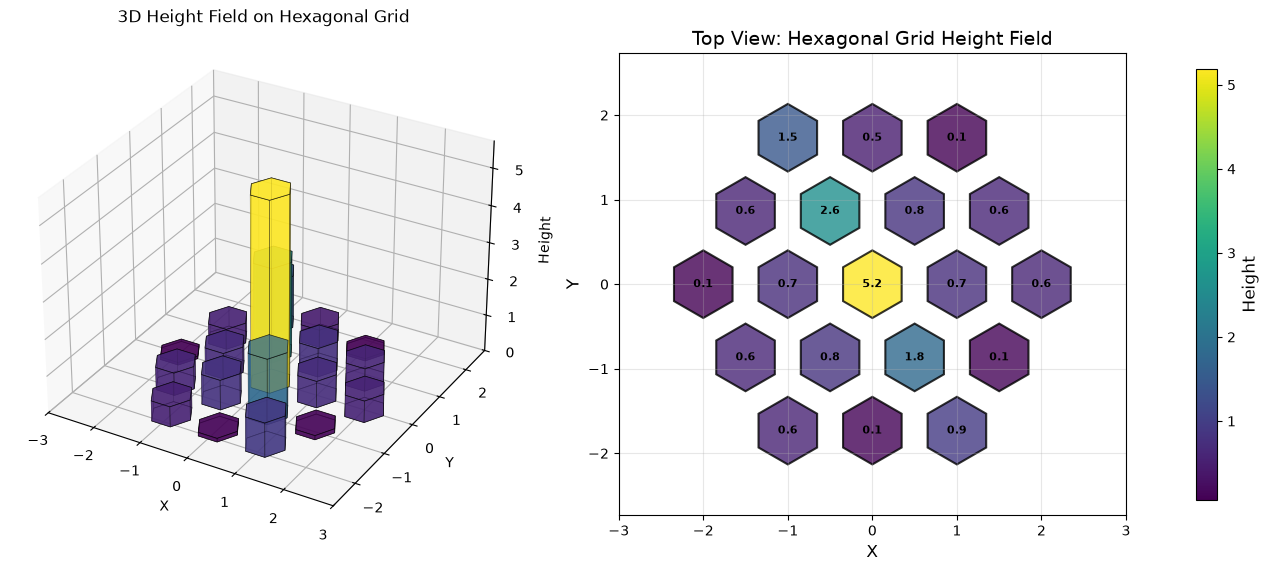

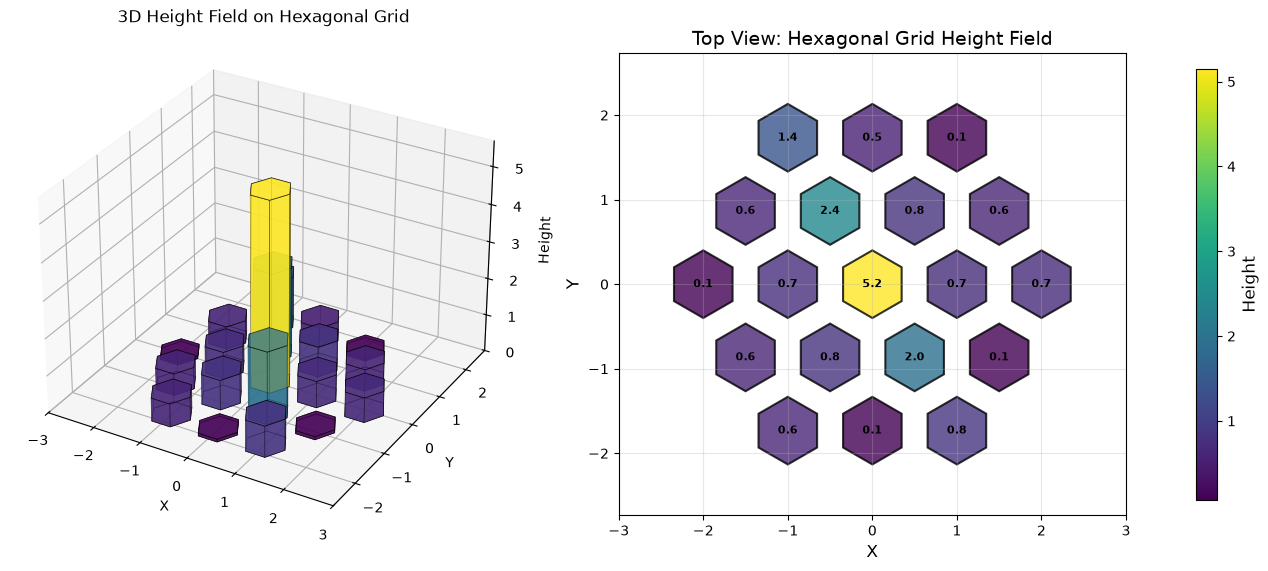

In [15]:
display_scale = 10  # arbitrary visual amplification, for readability in the hex-height plot

for i in range(len(uf_2d_batch1)):
    signals = collect_subpixel_signals(uf_2d_batch1[i], x_min, y_min, dx, dy, core_centers)
    standardized = np.zeros(N_SIGNALS)
    standardized[ideal_permutation] = signals * display_scale
    display_hex_grid_plots(ideal_grid_positions, standardized)


For a specula-free, pure numpy-vs-JAX / batched-vs-one-at-a-time efficiency
comparison of the `propagate()` step used above, see `Batched.ipynb`.